<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif;">
  <h1 dir="rtl" style="direction: rtl; text-align: right;">یادگیری مقابله‌ای (<span dir="ltr">Contrastive Learning</span>)، از اصول اولیه تا <span dir="ltr">SimCLR</span> (پاسخ‌ها / <span dir="ltr">Solutions</span>)</h1>
</div>


In [ ]:
import math
import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import torchvision
import torchvision.transforms as T

torch.manual_seed(1001)
np.random.seed(1001)
random.seed(1001)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


device: cuda


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h1 dir="rtl" style="direction: rtl; text-align: right;">بخش ۱ · چرا یادگیری مقابله‌ای؟ (<span dir="ltr">contrastive learning</span>)</h1>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    یادگیری بانظارت (<span dir="ltr">Supervised Learning</span>)، مدل‌ها را وادار به حفظ کردن مرزهای تصمیم‌گیری برچسب‌گذاری‌شده توسط کاربر می‌کند. در مقابل، یادگیری مقابله‌ای خودنظارتی (<span dir="ltr">Self-Supervised Contrastive Learning</span>) یک کدگذار (<span dir="ltr">Encoder</span>) را ملزم می‌سازد تا دو ویژگی هندسی متضاد را بهینه‌سازی کند:
  </p>
  <ol dir="rtl" style="direction: rtl; text-align: right; padding-right: 25px;">
    <li><strong>ناورایی یا هم‌ترازی (<span dir="ltr">Invariance / Alignment</span>):</strong> دو نمای دستکاری‌شده و تصادفی (<span dir="ltr">Corrupted views</span>) از یک نمونه یکسان، باید به بازنمایی‌های نزدیک به هم بر روی یک منیفلد (<span dir="ltr">Manifold</span>) نگاشت شوند.</li>
    <li><strong>تمایز یا یکنواختی (<span dir="ltr">Discrimination / Uniformity</span>):</strong> بازنمایی‌های نمونه‌های متمایز باید یکدیگر را دفع کنند، به گونه‌ای که اطلاعات به بیشترین میزان ممکن در سراسر فضای پنهان (<span dir="ltr">Latent Space</span>) حفظ شود.</li>
  </ol>
</div>


In [2]:
# بارگذاری مجموعه داده CIFAR-10 (Loading CIFAR-10 Dataset)
data_root = "./data"
cifar_train_raw = torchvision.datasets.CIFAR10(data_root, train=True, download=True)
cifar_test_raw = torchvision.datasets.CIFAR10(data_root, train=False, download=True)
classes = cifar_train_raw.classes
print("کلاس‌ها (Classes):", classes)


100%|██████████| 170M/170M [28:56<00:00, 98.2kB/s]


کلاس‌ها (Classes): ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h3 dir="rtl" style="direction: rtl; text-align: right;">خط لوله داده‌افزایی (<span dir="ltr">Data Augmentation Pipeline</span>)</h3>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    سیاست داده‌افزایی تصادفی (<span dir="ltr">Stochastic Augmentation Policy</span>) شامل برش و تغییر اندازه تصادفی (<span dir="ltr">Random Resized Crop</span>)، چرخش یا وارونگی افقی تصادفی (<span dir="ltr">Random Horizontal Flip</span>)، آشفتگی رنگ (<span dir="ltr">Color Jitter</span>)، تبدیل به مقیاس خاکستری (<span dir="ltr">Grayscale Conversion</span>) و تاری گاوسی (<span dir="ltr">Gaussian Blur</span>) است.
  </p>
</div>


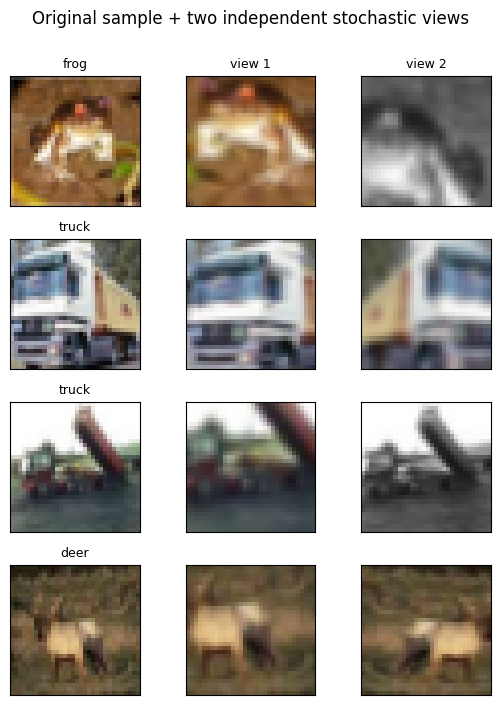

In [3]:
# تعریف خط لوله داده‌افزایی مدل SimCLR
simclr_augment = T.Compose([
    T.RandomResizedCrop(32, scale=(0.2, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomApply([T.ColorJitter(0.4, 0.4, 0.4, 0.1)], p=0.1),
    T.RandomGrayscale(p=0.2),
    T.RandomApply([T.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0))], p=0.1),
    T.ToTensor(),
])

fig, axes = plt.subplots(4, 3, figsize=(5.5, 7))
for row, index in enumerate([0, 1, 2, 3]):
    image, label = cifar_train_raw[index]
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(classes[label], fontsize=9)
    axes[row, 1].imshow(simclr_augment(image).permute(1, 2, 0))
    axes[row, 2].imshow(simclr_augment(image).permute(1, 2, 0))
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 1].set_title("view 1", fontsize=9)
axes[0, 2].set_title("view 2", fontsize=9)
plt.suptitle("Original sample + two independent stochastic views", y=1.0)
plt.tight_layout()
plt.show()


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h1 dir="rtl" style="direction: rtl; text-align: right;">بخش ۲ · جعبه‌ابزار ریاضی</h1>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    شباهت کسینوسی (<span dir="ltr">Cosine Similarity</span>) با نرمال‌سازی اندازه بردارهای تعبیه‌سازی (<span dir="ltr">Embedding Magnitudes</span>)، صرفاً هم‌جهتی و توافق زاویه‌ای (<span dir="ltr">Directional Agreement</span>) را می‌سنجد:
  </p>
  <div dir="ltr" style="direction: ltr; text-align: center; margin: 1em 0;">
    $$\mathrm{sim}(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u}\cdot\mathbf{v}}{\|\mathbf{u}\|\,\|\mathbf{v}\|} \in [-1, 1].$$
  </div>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    برای بردارهای یکه (<span dir="ltr">Unit Vectors</span>) با شرط <span dir="ltr">$\|\mathbf{u}\| = \|\mathbf{v}\| = 1$</span> بر روی ابرکره (<span dir="ltr">Hypersphere $S^{d-1}$</span>)، فاصله اقلیدسی (<span dir="ltr">Euclidean Distance</span>) مستقیماً بازتاب‌دهنده شباهت کسینوسی است:
  </p>
  <div dir="ltr" style="direction: ltr; text-align: center; margin: 1em 0;">
    $$\|\mathbf{u} - \mathbf{v}\|^2 = \|\mathbf{u}\|^2 + \|\mathbf{v}\|^2 - 2\,\mathbf{u}\cdot\mathbf{v} = 2 - 2\,\mathrm{sim}(\mathbf{u}, \mathbf{v}).$$
  </div>
</div>


In [4]:
# راستی‌آزمایی رابطه هندسی فاصله اقلیدسی و شباهت کسینوسی برای بردارهای نرمال‌شده روی ابرکره
torch.manual_seed(1001)
u = F.normalize(torch.randn(1000, 64), dim=1)
v = F.normalize(torch.randn(1000, 64), dim=1)
euclidean_sq = ((u - v) ** 2).sum(dim=1)
cosine = (u * v).sum(dim=1)
print("بیشینه اختلاف مطلق | ||u-v||^2 - (2 - 2 cos theta) |:",
      (euclidean_sq - (2 - 2 * cosine)).abs().max().item())


بیشینه اختلاف مطلق | ||u-v||^2 - (2 - 2 cos theta) |: 4.76837158203125e-07


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <p dir="rtl" style="direction: rtl; text-align: right;">
    <strong>سافت‌مکس با مقیاس دما (<span dir="ltr">Temperature-scaled Softmax</span>).</strong> برای بردار لاجیت‌ها (<span dir="ltr">Logits</span>) <span dir="ltr">$\mathbf{s} = (s_1, \dots, s_K)$</span> و پارامتر دما (<span dir="ltr">Temperature Parameter</span>) <span dir="ltr">$\tau > 0$</span>:
  </p>
  <div dir="ltr" style="direction: ltr; text-align: center; margin: 1em 0;">
    $$p_k = \frac{e^{s_k/\tau}}{\sum_{j=1}^K e^{s_j/\tau}}.$$
  </div>
</div>


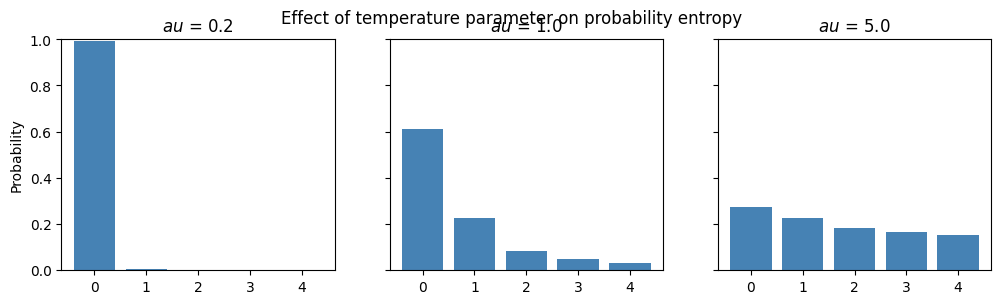

In [5]:
logits = torch.tensor([3.0, 2.0, 1.0, 0.5, 0.0])
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, tau in zip(axes, [0.2, 1.0, 5.0]):
    ax.bar(range(len(logits)), F.softmax(logits / tau, dim=0).numpy(), color="steelblue")
    ax.set_title(rf"$	au$ = {tau}")
    ax.set_xticks(range(len(logits)))
    ax.set_ylim(0, 1)
axes[0].set_ylabel("Probability")
plt.suptitle("Effect of temperature parameter on probability entropy")
plt.show()


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h3 dir="rtl" style="direction: rtl; text-align: right;">مبانی نظری و اثبات‌های ریاضی برای بخش ۲</h3>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    <strong>گزاره ۲.۱ ناورایی مقیاس و هندسه ابرکره.</strong>
  </p>
  <ol dir="rtl" style="direction: rtl; text-align: right; padding-right: 25px;">
    <li><em>ناورایی مقیاس (<span dir="ltr">Scale Invariance</span>):</em> به ازای هر اسکالر <span dir="ltr">$\alpha > 0$</span> و بردارهای غیرصفر <span dir="ltr">$\mathbf{u}, \mathbf{v} \in \mathbb{R}^d$</span>، داریم: <span dir="ltr">$\mathrm{sim}(\alpha \mathbf{u}, \mathbf{v}) = \mathrm{sim}(\mathbf{u}, \mathbf{v})$</span>.</li>
    <li><em>هم‌ریختی ترتیبی (<span dir="ltr">Order Isomorphism</span>):</em> برای بردارهای یکه <span dir="ltr">$\|\mathbf{u}\| = \|\mathbf{v}\| = 1$</span>، رتبه‌بندی جفت‌ها بر اساس فاصله اقلیدسی (<span dir="ltr">Euclidean Distance</span>)، کاملاً هم‌ارز با رتبه‌بندی معکوس آن‌ها بر پایه شباهت کسینوسی (<span dir="ltr">Cosine Similarity</span>) است.</li>
  </ol>
  <p dir="rtl" style="direction: rtl; text-align: right;"><em>اثبات (<span dir="ltr">Proof</span>).</em></p>
  <ol dir="rtl" style="direction: rtl; text-align: right; padding-right: 25px;">
    <li>
      طبق تعریف شباهت کسینوسی:
      <div dir="ltr" style="direction: ltr; text-align: center; margin: 0.8em 0;">
        $$\mathrm{sim}(\alpha\mathbf{u}, \mathbf{v}) = \frac{(\alpha\mathbf{u})\cdot\mathbf{v}}{\|\alpha\mathbf{u}\|\,\|\mathbf{v}\|} = \frac{\alpha(\mathbf{u}\cdot\mathbf{v})}{\alpha\|\mathbf{u}\|\,\|\mathbf{v}\|} = \frac{\mathbf{u}\cdot\mathbf{v}}{\|\mathbf{u}\|\,\|\mathbf{v}\|} = \mathrm{sim}(\mathbf{u}, \mathbf{v}).$$
      </div>
    </li>
    <li>
      با بسط دادن نرم توان دو (<span dir="ltr">Squared Euclidean Norm</span>): <span dir="ltr">$\|\mathbf{u} - \mathbf{v}\|^2 = \|\mathbf{u}\|^2 + \|\mathbf{v}\|^2 - 2(\mathbf{u}\cdot\mathbf{v}) = 2 - 2\,\mathrm{sim}(\mathbf{u}, \mathbf{v})$</span>. از آنجا که تابع <span dir="ltr">$g(s) = 2 - 2s$</span> بر روی بازه <span dir="ltr">$[-1, 1]$</span> اکیداً نزولی یکنواخت است:
      <div dir="ltr" style="direction: ltr; text-align: center; margin: 0.8em 0;">
        $$\|\mathbf{u}_1 - \mathbf{v}_1\|^2 < \|\mathbf{u}_2 - \mathbf{v}_2\|^2 \iff \mathrm{sim}(\mathbf{u}_1, \mathbf{v}_1) > \mathrm{sim}(\mathbf{u}_2, \mathbf{v}_2). \quad \blacksquare$$
      </div>
    </li>
  </ol>
  <hr style="margin: 1.5em 0;" />
  <p dir="rtl" style="direction: rtl; text-align: right;">
    <strong>گزاره ۲.۲ حدود دما و اشباع گرادیان.</strong><br />
    فرض کنید <span dir="ltr">$\mathbf{s} \in \mathbb{R}^K$</span> دارای بیشینه یکتای <span dir="ltr">$s_{\max} = \max_j s_j$</span> بوده و <span dir="ltr">$p_k(\tau) = \frac{e^{s_k/\tau}}{\sum_{j=1}^K e^{s_j/\tau}}$</span> باشد. در این صورت:
  </p>
  <ol dir="rtl" style="direction: rtl; text-align: right; padding-right: 25px;">
    <li><span dir="ltr">$\lim_{\tau \to 0^+} p_k(\tau) = \mathbb{1}[s_k = s_{\max}]$</span>.</li>
    <li><span dir="ltr">$\lim_{\tau \to \infty} p_k(\tau) = \frac{1}{K}$</span>.</li>
    <li>گرادیان (<span dir="ltr">Gradient</span>) <span dir="ltr">$\frac{\partial p_k}{\partial s_k} = \frac{1}{\tau} p_k (1 - p_k)$</span> در هر دو حد به صفر میل می‌کند (ناپدید شدن گرادیان / <span dir="ltr">Vanishing Gradients</span>): (<span dir="ltr">$\lim_{\tau \to 0^+} \frac{\partial p_k}{\partial s_k} = 0$</span> و <span dir="ltr">$\lim_{\tau \to \infty} \frac{\partial p_k}{\partial s_k} = 0$</span>).</li>
  </ol>
  <p dir="rtl" style="direction: rtl; text-align: right;"><em>اثبات (<span dir="ltr">Proof</span>).</em></p>
  <ol dir="rtl" style="direction: rtl; text-align: right; padding-right: 25px;">
    <li>
      فاکتورگیری از <span dir="ltr">$e^{s_{\max}/\tau}$</span> در صورت و مخرج کسر:
      <div dir="ltr" style="direction: ltr; text-align: center; margin: 0.8em 0;">
        $$p_k(\tau) = \frac{e^{(s_k - s_{\max})/\tau}}{1 + \sum_{j \neq \max} e^{(s_j - s_{\max})/\tau}}.$$
      </div>
      برای <span dir="ltr">$j \neq \max$</span> داریم <span dir="ltr">$s_j - s_{\max} < 0$</span>، که نتیجه می‌دهد <span dir="ltr">$\lim_{\tau \to 0^+} e^{(s_j - s_{\max})/\tau} = 0$</span>. به ازای <span dir="ltr">$k = \max$</span> صورت کسر برابر با <span dir="ltr">$e^0 = 1$</span> می‌شود که حد ۱ را می‌دهد. به ازای <span dir="ltr">$k \neq \max$</span> صورت کسر صفر شده و حد ۰ به دست می‌آید.
    </li>
    <li>
      از آنجا که <span dir="ltr">$\lim_{\tau \to \infty} s_j / \tau = 0$</span>، برای هر <span dir="ltr">$j$</span> داریم <span dir="ltr">$e^{s_j/\tau} \to 1$</span>، بنابراین <span dir="ltr">$p_k \to \frac{1}{K}$</span>.
    </li>
    <li>
      با مشتق‌گیری طبق قاعده خارج قسمت (<span dir="ltr">Quotient Rule</span>):
      <div dir="ltr" style="direction: ltr; text-align: center; margin: 0.8em 0;">
        $$\frac{\partial p_k}{\partial s_k} = \frac{\frac{1}{\tau}e^{s_k/\tau}\sum_j e^{s_j/\tau} - e^{s_k/\tau}\frac{1}{\tau}e^{s_k/\tau}}{\left(\sum_j e^{s_j/\tau}\right)^2} = \frac{1}{\tau}p_k(1 - p_k).$$
      </div>
      وقتی <span dir="ltr">$\tau \to 0^+$</span>، مقدار <span dir="ltr">$p_k$</span> به ۰ یا ۱ میل می‌کند؛ در نتیجه عبارت <span dir="ltr">$p_k(1-p_k)$</span> به طور نمایی سریع‌تر از میل <span dir="ltr">$\tau \to 0$</span> به سمت صفر می‌رود. زمانی که <span dir="ltr">$\tau \to \infty$</span>، مقدار <span dir="ltr">$p_k(1-p_k) \to \frac{K-1}{K^2}$</span> خواهد بود، در حالی که ضریب مقیاس <span dir="ltr">$\frac{1}{\tau} \to 0$</span> می‌شود. بنابراین گرادیان‌ها (<span dir="ltr">Gradients</span>) در هر دو کران ناپدید می‌شوند. <span dir="ltr">$\blacksquare$</span>
    </li>
  </ol>
</div>


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h1 dir="rtl" style="direction: rtl; text-align: right;">بخش ۳ · یادگیری از طریق تمایز (<span dir="ltr">§3 · Learning by discrimination</span>)</h1>
  <h2 dir="rtl" style="direction: rtl; text-align: right;">۳.۱ تخمین مقابله‌ای نویز (<span dir="ltr">3.1 Noise-Contrastive Estimation - NCE</span>)</h2>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    با در نظر گرفتن توزیع نرمال‌نشده داده‌ها <span dir="ltr">$p_d$</span> و توزیع معلوم نویز مرجع <span dir="ltr">$p_n$</span>، روش <span dir="ltr">NCE</span> یک طبقه‌بندی‌کننده دودویی لجستیک (<span dir="ltr">Logistic Binary Classifier</span>) را با تابع امتیاز (<span dir="ltr">Score Function</span>) <span dir="ltr">$s(x)$</span> آموزش می‌دهد:
  </p>
  <div dir="ltr" style="direction: ltr; text-align: center; margin: 1em 0;">
    $$\mathcal{L}_{\mathrm{NCE}} = -\,\mathbb{E}_{x \sim p_d}\big[\log \sigma(s(x))\big] - \mathbb{E}_{x \sim p_n}\big[\log\big(1 - \sigma(s(x))\big)\big].$$
  </div>
</div>


In [ ]:
# پاسخ: تخمین‌گر نسبت چگالی با NCE (Solution: NCE Density Ratio Estimator)
torch.manual_seed(1001)
data_samples = torch.randn(20000, 1) + 1.0
noise_samples = torch.randn(20000, 1)

score = nn.Linear(1, 1)
optimizer = torch.optim.Adam(score.parameters(), lr=0.05)
inputs = torch.cat([data_samples, noise_samples])
targets = torch.cat([torch.ones(20000), torch.zeros(20000)])

for step in range(500):
    optimizer.zero_grad()
    loss = F.binary_cross_entropy_with_logits(score(inputs).squeeze(1), targets)
    loss.backward()
    optimizer.step()

w, b = score.weight.item(), score.bias.item()
print(f"امتیاز آموخته‌شده (Learned score):      s(x) = {w:.3f} * x + {b:.3f}")
print(f"نسبت نظری (Theoretical ratio): log p_d/p_n = 1.000 * x - 0.500")


امتیاز آموخته‌شده (Learned score):      s(x) = 0.990 * x + -0.488
نسبت نظری (Theoretical ratio): log p_d/p_n = 1.000 * x - 0.500


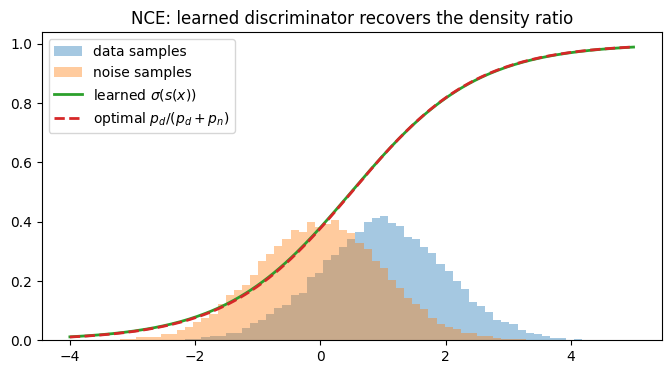

In [ ]:

xs = torch.linspace(-4, 5, 200).unsqueeze(1)
with torch.no_grad():
    learned = torch.sigmoid(score(xs)).squeeze(1)
pd = torch.distributions.Normal(1.0, 1.0).log_prob(xs).exp()
pn = torch.distributions.Normal(0.0, 1.0).log_prob(xs).exp()
optimal = pd / (pd + pn)

plt.figure(figsize=(8, 4))
plt.hist(data_samples.numpy(), bins=60, alpha=0.4, density=True, label="data samples")
plt.hist(noise_samples.numpy(), bins=60, alpha=0.4, density=True, label="noise samples")
plt.plot(xs.numpy(), learned.numpy(), lw=2, label=r"learned $\sigma(s(x))$")
plt.plot(xs.numpy(), optimal.numpy(), "--", lw=2, label=r"optimal $p_d/(p_d+p_n)$")
plt.legend()
plt.title("NCE: learned discriminator recovers the density ratio")
plt.show()


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h2 dir="rtl" style="direction: rtl; text-align: right;">۳.۲ تابع زیان InfoNCE </h2>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    روش <span dir="ltr">InfoNCE</span> ایده <span dir="ltr">NCE</span> را به یک مسئله طبقه‌بندی دسته‌ای (<span dir="ltr">Categorical Classification</span>) با <span dir="ltr">$K$</span> حالت تعمیم می‌دهد؛ شامل یک لنگر (<span dir="ltr">Anchor</span>) به نام <span dir="ltr">$c$</span>، یک کاندید مثبت (<span dir="ltr">Positive Candidate</span>) به نام <span dir="ltr">$x^+$</span> و <span dir="ltr">$K-1$</span> کاندید منفی (<span dir="ltr">Negative Candidates</span>) به نام‌های <span dir="ltr">$x_j^-$</span>:
  </p>
  <div dir="ltr" style="direction: ltr; text-align: center; margin: 1em 0;">
    $$\mathcal{L}_{\mathrm{InfoNCE}} = -\,\mathbb{E}\left[\log \frac{\exp\big(s(x^+, c)/\tau\big)}{\exp\big(s(x^+, c)/\tau\big) + \sum_{j=1}^{K-1} \exp\big(s(x^-_j, c)/\tau\big)}\right].$$
  </div>
</div>


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h3 dir="rtl" style="direction: rtl; text-align: right;">مبانی نظری و اثبات‌های ریاضی برای بخش ۳</h3>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    <strong>قضیه ۳.۱ (تشخیص‌دهنده بهینه در تخمین مقابله‌ای نویز - <span dir="ltr">Optimal Discriminator in NCE</span>).</strong><br />
    تابع امتیاز <span dir="ltr">$s^*(x)$</span> که تابع زیان <span dir="ltr">$\mathcal{L}_{\mathrm{NCE}}$</span> را به طور سراسری کمینه (<span dir="ltr">Globally Minimize</span>) می‌کند، در رابطه زیر صدق می‌نماید:
  </p>
  <div dir="ltr" style="direction: ltr; text-align: center; margin: 0.8em 0;">
    $$\sigma(s^*(x)) = \frac{p_d(x)}{p_d(x) + p_n(x)} \iff s^*(x) = \log \frac{p_d(x)}{p_n(x)}.$$
  </div>
  <p dir="rtl" style="direction: rtl; text-align: right;"><em>اثبات (<span dir="ltr">Proof</span>).</em></p>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    امید ریاضی (<span dir="ltr">Expectation</span>) را به صورت انتگرال بر روی فضای نمونه <span dir="ltr">$\mathcal{X}$</span> می‌نویسیم:
  </p>
  <div dir="ltr" style="direction: ltr; text-align: center; margin: 0.8em 0;">
    $$\mathcal{L}_{\mathrm{NCE}}(s) = -\int_{\mathcal{X}} \Big[ p_d(x) \log \sigma(s(x)) + p_n(x) \log\big(1 - \sigma(s(x))\big) \Big] dx.$$
  </div>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    از آنجا که <span dir="ltr">$s(x)$</span> را می‌توان در هر نقطه <span dir="ltr">$x$</span> مستقلاً تغییر داد، عبارت زیر انتگرال را به صورت نقطه‌ای کمینه می‌کنیم. با قرار دادن <span dir="ltr">$a = \sigma(s(x)) \in (0, 1)$</span>، تابع <span dir="ltr">$J(a) = -p_d(x)\log a - p_n(x)\log(1-a)$</span> را تعریف می‌نماییم. با مشتق‌گیری نسبت به <span dir="ltr">$a$</span>:
  </p>
  <div dir="ltr" style="direction: ltr; text-align: center; margin: 0.8em 0;">
    $$\frac{dJ}{da} = -\frac{p_d(x)}{a} + \frac{p_n(x)}{1 - a} = 0 \implies p_d(x)(1 - a) = p_n(x)a \implies a^* = \frac{p_d(x)}{p_d(x) + p_n(x)}.$$
  </div>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    از آنجا که مشتق دوم <span dir="ltr">$\frac{d^2J}{da^2} = \frac{p_d(x)}{a^2} + \frac{p_n(x)}{(1-a)^2} > 0$</span> همواره مثبت است، این نقطه اکسترمم یک کمینه مطلق و یکتای سراسری (<span dir="ltr">Unique Global Minimum</span>) است. با وارون‌سازی تابع پیوند لجستیک (<span dir="ltr">Logistic Link</span>) <span dir="ltr">$a = \frac{1}{1 + e^{-s}}$</span> خواهیم داشت:
  </p>
  <div dir="ltr" style="direction: ltr; text-align: center; margin: 0.8em 0;">
    $$s^*(x) = \log \left(\frac{a^*}{1 - a^*}\right) = \log \left(\frac{\frac{p_d(x)}{p_d(x)+p_n(x)}}{\frac{p_n(x)}{p_d(x)+p_n(x)}}\right) = \log \frac{p_d(x)}{p_n(x)}. \quad \blacksquare$$
  </div>
  <hr style="margin: 1.5em 0;" />
  <p dir="rtl" style="direction: rtl; text-align: right;">
    <strong>قضیه ۳.۲ (پویایی گرادیان در InfoNCE - <span dir="ltr">InfoNCE Gradient Dynamics</span>).</strong><br />
    برای یک لنگر با امتیازهای نامزد <span dir="ltr">$\mathbf{s} = (s_1, \dots, s_K)$</span> که در آن اندیس <span dir="ltr">$p$</span> نشان‌دهنده جفت مثبت (<span dir="ltr">Positive Pair</span>) است، فرض کنید <span dir="ltr">$\ell = -\log \frac{e^{s_p/\tau}}{\sum_{j=1}^K e^{s_j/\tau}}$</span> و <span dir="ltr">$q_k = \mathrm{softmax}(\mathbf{s}/\tau)_k$</span> باشند. در این صورت گرادیان (<span dir="ltr">Gradient</span>) تابع زیان نسبت به هر امتیاز برابر است با:
  </p>
  <div dir="ltr" style="direction: ltr; text-align: center; margin: 0.8em 0;">
    $$\frac{\partial \ell}{\partial s_k} = \frac{1}{\tau}\Big(q_k - \mathbb{1}[k = p]\Big).$$
  </div>
  <p dir="rtl" style="direction: rtl; text-align: right;"><em>اثبات (<span dir="ltr">Proof</span>).</em></p>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    تابع زیان را به صورت <span dir="ltr">$\ell = -\frac{s_p}{\tau} + \log \sum_{j=1}^K e^{s_j/\tau}$</span> بازنویسی می‌کنیم. با مشتق‌گیری نسبت به <span dir="ltr">$s_k$</span>:
  </p>
  <div dir="ltr" style="direction: ltr; text-align: center; margin: 0.8em 0;">
    $$\frac{\partial \ell}{\partial s_k} = -\frac{1}{\tau}\mathbb{1}[k = p] + \frac{\frac{1}{\tau}e^{s_k/\tau}}{\sum_{j=1}^K e^{s_j/\tau}} = \frac{1}{\tau}\Big(q_k - \mathbb{1}[k = p]\Big). \quad \blacksquare$$
  </div>
</div>


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h1 dir="rtl" style="direction: rtl; text-align: right;">بخش ۴ · تابع زیان NT-Xent: تابع زیان اختصاصی SimCLR (<span dir="ltr">§4 · NT-Xent: SimCLR's loss</span>)</h1>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    برای یک دسته (<span dir="ltr">Batch</span>) با اندازه <span dir="ltr">$N$</span> تصویر، تولید دو نمای افزوده برای هر تصویر به <span dir="ltr">$2N$</span> بردار بازنمایی منجر می‌شود. برای نمای لنگر <span dir="ltr">$i$</span>، جفت مثبت منطبق با آن <span dir="ltr">$\mathrm{pos}(i) = (i + N) \bmod 2N$</span> است و <span dir="ltr">$2N-2$</span> نمای دیگر در دسته به عنوان جفت‌های منفی عمل می‌کنند:
  </p>
  <div dir="ltr" style="direction: ltr; text-align: center; margin: 1em 0;">
    $$\ell(i, j) = -\log \frac{\exp\big(\mathrm{sim}(\mathbf{z}_i, \mathbf{z}_j)/\tau\big)}{\sum_{k \neq i} \exp\big(\mathrm{sim}(\mathbf{z}_i, \mathbf{z}_k)/\tau\big)}, \qquad \mathcal{L}_{\text{NT-Xent}} = \frac{1}{2N}\sum_{i=1}^{2N} \ell\big(i, \mathrm{pos}(i)\big).$$
  </div>
</div>


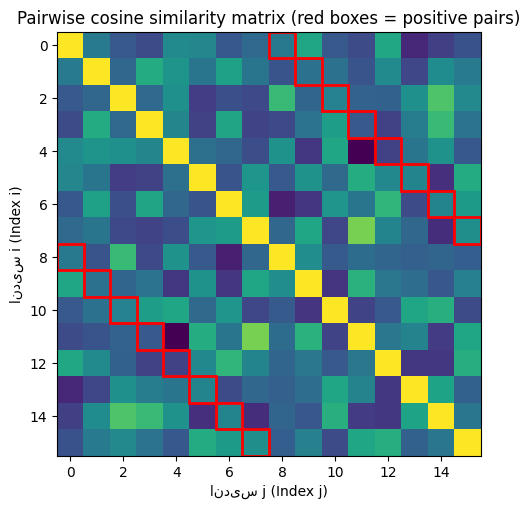

In [7]:
torch.manual_seed(1)
n = 8
z = F.normalize(torch.randn(2 * n, 16), dim=1)
similarity = (z @ z.T).numpy()

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.imshow(similarity, cmap="viridis")

for i in range(2 * n):
    j = (i + n) % (2 * n)
    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="red", lw=2))
ax.set_xlabel("اندیس j (Index j)")
ax.set_ylabel("اندیس i (Index i)")
ax.set_title("Pairwise cosine similarity matrix (red boxes = positive pairs)")
plt.show()


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h3 dir="rtl" style="direction: rtl; text-align: right;">مبانی نظری و اثبات‌های ریاضی برای بخش ۴</h3>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    <strong>قضیه ۴.۱ (مقدار NT-Xent در شرایط فروپاشی کامل بازنمایی - <span dir="ltr">NT-Xent Value Under Complete Representation Collapse</span>).</strong><br />
    اگر تمامی بازنمایی‌ها در یک دسته به یک بردار کاملاً یکسان فروپاشی کنند (<span dir="ltr">Representation Collapse</span>: <span dir="ltr">$\mathbf{z}_1 = \dots = \mathbf{z}_{2N} = \mathbf{z}$</span>)، تابع زیان <span dir="ltr">NT-Xent</span> نسبت به مقدار <span dir="ltr">$\mathbf{z}$</span> و دما <span dir="ltr">$\tau$</span> ناوراست (<span dir="ltr">Invariant</span>) و رابطه زیر برقرار است:
  </p>
  <div dir="ltr" style="direction: ltr; text-align: center; margin: 0.8em 0;">
    $$\mathcal{L}_{\mathrm{NT-Xent}} = \log(2N - 1).$$
  </div>
  <p dir="rtl" style="direction: rtl; text-align: right;"><em>اثبات (<span dir="ltr">Proof</span>).</em></p>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    برای بردارهای نرمال‌سازی‌شده روی ابرکره که در آن‌ها <span dir="ltr">$\mathbf{z}_i = \mathbf{z}_j$</span> است، شباهت کسینوسی <span dir="ltr">$\mathrm{sim}(\mathbf{z}_i, \mathbf{z}_j) = 1$</span> برای تمام جفت‌ها صادق است. با قرار دادن در رابطه زیان تک‌نما <span dir="ltr">$\ell(i, \mathrm{pos}(i))$</span>:
  </p>
  <div dir="ltr" style="direction: ltr; text-align: center; margin: 0.8em 0;">
    $$\ell(i, \mathrm{pos}(i)) = -\log \frac{e^{1/\tau}}{\sum_{k \neq i} e^{1/\tau}} = -\log \frac{e^{1/\tau}}{(2N - 1)e^{1/\tau}} = -\log \frac{1}{2N - 1} = \log(2N - 1).$$
  </div>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    با میانگین‌گیری روی تمام <span dir="ltr">$2N$</span> نما، نتیجه به دست می‌آید: <span dir="ltr">$\mathcal{L}_{\mathrm{NT-Xent}} = \log(2N - 1)$</span>. <span dir="ltr">$\blacksquare$</span>
  </p>
  <hr style="margin: 1.5em 0;" />
  <p dir="rtl" style="direction: rtl; text-align: right;">
    <strong>قضیه ۴.۲ (رفتارهای مجانبی پارامتر دما - <span dir="ltr">Asymptotic Extremes of Temperature</span>).</strong>
  </p>
  <ol dir="rtl" style="direction: rtl; text-align: right; padding-right: 25px;">
    <li>
      زمانی که <span dir="ltr">$\tau \to 0^+$</span>، توزیع احتمال <span dir="ltr">$q$</span> روی نمونه‌های منفی صرفاً روی سخت‌ترین نمونه منفی (<span dir="ltr">Hardest Negative</span>) متمرکز می‌شود: <span dir="ltr">$j^* = \arg\max_{k \neq i, \mathrm{pos}(i)} \mathrm{sim}(\mathbf{z}_i, \mathbf{z}_k)$</span>. در این حالت، به‌روزرسانی گرادیان با مقیاس <span dir="ltr">$\mathcal{O}(1/\tau)$</span> رشد کرده و منجر به واریانس بسیار زیاد (<span dir="ltr">High Variance</span>) و ناپایداری بهینه‌سازی می‌شود.
    </li>
    <li>
      زمانی که <span dir="ltr">$\tau \to \infty$</span>، توزیع احتمال روی تمامی <span dir="ltr">$2N-1$</span> کاندید به توزیع یکنواخت همگرا می‌شود (<span dir="ltr">$q_k \to \frac{1}{2N-1}$</span>) و بزرگی گام گرادیان با مقیاس <span dir="ltr">$\mathcal{O}(1/\tau) \to 0$</span> ناپدید می‌گردد (<span dir="ltr">Vanishing Gradients</span>).
    </li>
  </ol>
  <p dir="rtl" style="direction: rtl; text-align: right;"><em>اثبات (<span dir="ltr">Proof</span>).</em></p>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    طبق قضیه ۳.۲، گرادیان نسبت به بردار <span dir="ltr">$\mathbf{z}_i$</span> برابر است با: <span dir="ltr">$\nabla_{\mathbf{z}_i} \ell = \frac{1}{\tau}\sum_{k \neq i} q_k (\mathbf{z}_k - \mathbf{z}_{\mathrm{pos}(i)})$</span>. وقتی <span dir="ltr">$\tau \to 0^+$</span>، بر اساس گزاره ۲.۲، <span dir="ltr">$q_{j^*} \to 1$</span> شده و بقیه <span dir="ltr">$q_k \to 0$</span> می‌گردند؛ بنابراین نیروی منفی منحصراً به سمت سخت‌ترین نمونه جهت می‌گیرد در حالی که ضریب مقیاس <span dir="ltr">$\frac{1}{\tau} \to \infty$</span> می‌شود. در مقابل، وقتی <span dir="ltr">$\tau \to \infty$</span>، مقدار <span dir="ltr">$q_k \to \frac{1}{2N-1}$</span> است که نتیجه می‌دهد <span dir="ltr">$\lim_{\tau \to \infty} \frac{1}{\tau}(q_k - \mathbb{1}[k=\mathrm{pos}(i)]) = 0$</span>. <span dir="ltr">$\blacksquare$</span>
  </p>
</div>


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h1 dir="rtl" style="direction: rtl; text-align: right;">بخش ۵ · مدل SimCLR در PyTorch (<span dir="ltr">§5 · SimCLR in PyTorch</span>)</h1>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    این چارچوب شامل یک ماژول داده‌افزایی تصویر (<span dir="ltr">Image Augmentation Module</span>)، یک کدگذار پایه یا انکودر بر پایه شبکه عصبی پیچشی (<span dir="ltr">CNN Backbone</span> مانند <span dir="ltr">ResNet-18</span>) به نام <span dir="ltr">$f(\cdot)$</span> که بردار ویژگی <span dir="ltr">$\mathbf{h} \in \mathbb{R}^{512}$</span> را استخراج می‌کند، یک سر پروجکشن چندلایه (<span dir="ltr">MLP Projection Head</span>) به نام <span dir="ltr">$g(\cdot)$</span> که نگاشت به فضای پنهان <span dir="ltr">$\mathbf{z} \in \mathbb{R}^{128}$</span> را انجام می‌دهد، و تابع زیان <span dir="ltr">NT-Xent</span> است.
  </p>
</div>


In [8]:
# پاسخ: کلاس TwoViewDataset (Solution: TwoViewDataset)
class TwoViewDataset(Dataset):
    def __init__(self, base, transform):
        self.base = base
        self.transform = transform

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        image, label = self.base[index]
        return self.transform(image), self.transform(image), label

train_two_views = TwoViewDataset(cifar_train_raw, simclr_augment)
v1, v2, y = train_two_views[0]
print(f"کلاس TwoViewDataset با موفقیت مقداردهی شد: {len(train_two_views)} نمونه. ابعاد نماها: {v1.shape}, {v2.shape}")
print(f"برچسب کلاس (Class label): {classes[y]}")


کلاس TwoViewDataset با موفقیت مقداردهی شد: 50000 نمونه. ابعاد نماها: torch.Size([3, 32, 32]), torch.Size([3, 32, 32])
برچسب کلاس (Class label): frog


In [9]:
# پاسخ: ماژول SimCLR با ستون فقرات ResNet-18 و پروجکتور چندلایه (Solution: SimCLR Module with ResNet-18 Backbone & MLP Projector)
class SimCLR(nn.Module):
    def __init__(self, projection_dim=128):
        super().__init__()
        backbone = torchvision.models.resnet18(weights=None)
        feature_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.encoder = backbone
        self.projection_head = nn.Sequential(
            nn.Linear(feature_dim, feature_dim),
            nn.ReLU(inplace=True),
            nn.Linear(feature_dim, projection_dim),
        )

    def forward(self, x):
        return self.projection_head(self.encoder(x))

test_model = SimCLR()
dummy_input = torch.randn(2, 3, 32, 32)
print("ابعاد خروجی کدگذار (Encoder output shape):", test_model.encoder(dummy_input).shape)
print("ابعاد خروجی پروجکتور (Projector output shape):", test_model(dummy_input).shape)


ابعاد خروجی کدگذار (Encoder output shape): torch.Size([2, 512])
ابعاد خروجی پروجکتور (Projector output shape): torch.Size([2, 128])


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h2 dir="rtl" style="direction: rtl; text-align: right;">۵.۱ تابع زیان NT-Xent: پیاده‌سازی مرجع در برابر پیاده‌سازی برداری (<span dir="ltr">NT-Xent: Reference vs Vectorized Implementation</span>)</h2>
</div>


In [10]:
# پاسخ: پیاده‌سازی ساده و مرجع مبتنی بر حلقه (Solution: Naive Reference Implementation (Loop-based))
def nt_xent_naive(z, temperature=0.5):
    n = z.shape[0] // 2
    z = F.normalize(z, dim=1)
    losses = []
    for i in range(2 * n):
        j = (i + n) % (2 * n)
        numerator = torch.exp(torch.sum(z[i] * z[j]) / temperature)
        denominator = 0.0
        for k in range(2 * n):
            if k != i:
                denominator = denominator + torch.exp(torch.sum(z[i] * z[k]) / temperature)
        losses.append(-torch.log(numerator / denominator))
    return torch.stack(losses).mean()


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h3 dir="rtl" style="direction: rtl; text-align: right;">برداری‌سازی تابع زیان NT-Xent (<span dir="ltr">Vectorization of NT-Xent</span>)</h3>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    حلقه‌های تو‌در‌توی مستقیم مقیاس‌پذیر نیستند. پیاده‌سازی برداری (<span dir="ltr">Vectorized Implementation</span>)، کل ماتریس شباهت با ابعاد <span dir="ltr">$(2N \times 2N)$</span> را به صورت موازی محاسبه می‌کند، درایه‌های روی قطر اصلی را با <span dir="ltr">$-\infty$</span> پر می‌کند (تا با توجه به <span dir="ltr">$e^{-\infty} = 0$</span> در سافت‌مکس، اثر مقایسه با خود حذف شود) و در نهایت آنتروپی متقاطع استاندارد را با استفاده از جایگشت اندیس‌های مثبت به عنوان برچسب‌های مرجع (<span dir="ltr">Ground Truth</span>) اعمال می‌نماید.
  </p>
</div>


In [11]:
# پاسخ: تابع زیان برداری‌شده NT-Xent (Solution: Vectorized NT-Xent Loss)
def nt_xent(z, temperature=0.5):
    n = z.shape[0] // 2
    z = F.normalize(z, dim=1)
    similarity = (z @ z.T) / temperature
    similarity.fill_diagonal_(float("-inf"))
    positive_index = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)]).to(z.device)
    return F.cross_entropy(similarity, positive_index)

torch.manual_seed(1001)
z_test = torch.randn(16, 8) * 2 + 3
for tau in [0.1, 0.5, 1.0]:
    slow = nt_xent_naive(z_test, tau).item()
    fast = nt_xent(z_test, tau).item()
    print(f"tau={tau:4.2f}  پیاده‌سازی حلقه={slow:.6f}  پیاده‌سازی برداری={fast:.6f}")
    assert torch.allclose(nt_xent_naive(z_test, tau), nt_xent(z_test, tau), atol=1e-5)
print("راستی‌آزمایی عددی با موفقیت انجام شد: پیاده‌سازی‌ها کاملاً منطبق هستند.")


tau=0.10  پیاده‌سازی حلقه=3.329759  پیاده‌سازی برداری=3.329759
tau=0.50  پیاده‌سازی حلقه=2.750335  پیاده‌سازی برداری=2.750335
tau=1.00  پیاده‌سازی حلقه=2.722840  پیاده‌سازی برداری=2.722840
راستی‌آزمایی عددی با موفقیت انجام شد: پیاده‌سازی‌ها کاملاً منطبق هستند.


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h2 dir="rtl" style="direction: rtl; text-align: right;">۵.۲ حلقه آموزش (<span dir="ltr">Training Loop</span>)</h2>
</div>


In [12]:
from tqdm import tqdm
# پاسخ: خط لوله کامل آموزش با AMP و ذخیره وضعیت / چک‌پوینت (Solution: Full Training Pipeline with AMP and Checkpointing)
def train_simclr(model, loader, epochs, lr, weight_decay, temperature,
                 checkpoint_path=None, log_every=10):
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    use_amp = device.type == "cuda"
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

    history = []
    start_epoch = 0
    if checkpoint_path is not None and Path(checkpoint_path).exists():
        state = torch.load(checkpoint_path, map_location=device)
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        history = state["history"]
        start_epoch = state["epoch"] + 1
        print(f"آموزش از نقطه ذخیره در دور {start_epoch} ادامه یافت (Resumed from checkpoint).")

    for epoch in range(start_epoch, epochs):
        model.train()
        losses = []
        for view1, view2, _ in tqdm(loader):
            x = torch.cat([view1.to(device, non_blocking=True),
                           view2.to(device, non_blocking=True)], dim=0)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=device.type, enabled=use_amp):
                z = model(x)
            loss = nt_xent(z.float(), temperature)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            losses.append(loss.item())
        history.append(sum(losses) / len(losses))
        scheduler.step()
        if (epoch + 1) % log_every == 0 or epoch == epochs - 1:
            print(f"دور (Epoch) {epoch + 1:4d}/{epochs}   زیان NT-Xent: {history[-1]:.4f}")
        if checkpoint_path is not None:
            torch.save({
                "epoch": epoch,
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(),
                "history": history,
            }, checkpoint_path)
    return history


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h3 dir="rtl" style="direction: rtl; text-align: right;">اجرای پیش‌آموزش مدل (<span dir="ltr">Pretraining</span>)</h3>
</div>


100%|██████████| 195/195 [00:29<00:00,  6.52it/s]


دور (Epoch)   10/20   زیان NT-Xent: 4.8274


100%|██████████| 195/195 [00:29<00:00,  6.63it/s]


دور (Epoch)   20/20   زیان NT-Xent: 4.7624


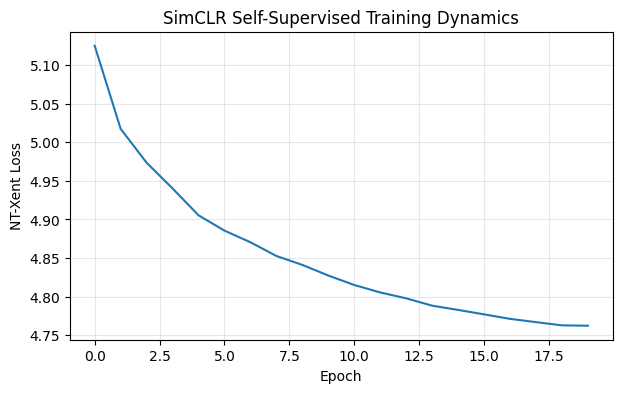

In [13]:
CONFIG = {
    "epochs": 20,
    "batch_size": 256,
    "lr": 1e-3,
    "weight_decay": 1e-6,
    "temperature": 0.5,
}

train_loader = DataLoader(
    train_two_views,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True,
)

simclr_model = SimCLR().to(device)
history = train_simclr(
    simclr_model,
    train_loader,
    CONFIG["epochs"],
    CONFIG["lr"],
    CONFIG["weight_decay"],
    CONFIG["temperature"],
    checkpoint_path="simclr_checkpoint.pt",
)
torch.save(simclr_model.state_dict(), "simclr_model.pt")

plt.figure(figsize=(7, 4))
plt.plot(history)
plt.xlabel("Epoch")
plt.ylabel("NT-Xent Loss")
plt.title("SimCLR Self-Supervised Training Dynamics")
plt.grid(alpha=0.3)
plt.show()


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h1 dir="rtl" style="direction: rtl; text-align: right;">بخش ۶ · پروتکل‌های ارزیابی بازنمایی (<span dir="ltr">§6 · Representation Evaluation Protocols</span>)</h1>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    برای سنجش کیفیت ویژگی‌های استخراج‌شده بدون دستکاری یا تنظیم دقیق (<span dir="ltr">Fine-tuning</span>) وزن‌های شبکه پایه (<span dir="ltr">Backbone</span>)، بازنمایی‌ها تثبیت (<span dir="ltr">Freeze</span>) شده و با دو پروتکل ارزیابی می‌شوند:
  </p>
  <ol dir="rtl" style="direction: rtl; text-align: right; padding-right: 25px;">
    <li><strong>پروب خطی (<span dir="ltr">Linear Probe</span>):</strong> برازش یک لایه رگرسیون لجستیک منفرد بر روی ویژگی‌های تثبیت‌شده ۵۱۲ بعدی خروجی کدگذار (<span dir="ltr">Frozen 512-dimensional Encoder Features</span>).</li>
    <li><strong>طبقه‌بندی‌کننده کا-نزدیک‌ترین همسایه (<span dir="ltr">k-NN Classifier</span>):</strong> طبقه‌بندی ناپارامتری بر پایه رأی‌گیری اکثریت میان <span dir="ltr">$k$</span> نزدیک‌ترین همسایه بر اساس فاصله کسینوسی (<span dir="ltr">Cosine Distance</span>).</li>
  </ol>
</div>


In [14]:
# پاسخ: استخراج ویژگی و پروب‌های ارزیابی (Solution: Feature Extraction & Evaluation Probes)
eval_transform = T.Compose([T.ToTensor()])

@torch.no_grad()
def extract_features(encoder, loader):
    encoder.eval()
    all_features, all_labels = [], []
    for x, y in loader:
        h = encoder(x.to(device))
        all_features.append(h.cpu())
        all_labels.append(y)
    return torch.cat(all_features), torch.cat(all_labels)

def train_linear_probe(features, labels, steps=500, lr=1e-3):
    probe = nn.Linear(features.shape[1], 10).to(device)
    optimizer = torch.optim.Adam(probe.parameters(), lr=lr)
    x = features.to(device)
    y = labels.to(device)
    for _ in range(steps):
        optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(probe(x), y)
        loss.backward()
        optimizer.step()
    return probe

def linear_probe_accuracy(probe, features, labels):
    with torch.no_grad():
        predictions = probe(features.to(device)).argmax(dim=1).cpu()
    return (predictions == labels).float().mean().item()

def knn_accuracy(train_features, train_labels, test_features, test_labels, k=20, chunk=1024):
    train_features = F.normalize(train_features, dim=1).to(device)
    train_labels = train_labels.to(device)
    test_features = F.normalize(test_features, dim=1)
    correct = 0
    with torch.no_grad():
        for start in range(0, len(test_features), chunk):
            block = test_features[start:start + chunk].to(device)
            neighbors = (block @ train_features.T).topk(k, dim=1).indices
            votes = torch.zeros(block.shape[0], 10, device=device)
            votes.scatter_add_(1, train_labels[neighbors], torch.ones(neighbors.shape, device=device))
            correct += (votes.argmax(dim=1) == test_labels[start:start + chunk].to(device)).sum().item()
    return correct / len(test_features)


In [15]:
train_eval = torchvision.datasets.CIFAR10(data_root, train=True, transform=eval_transform, download=True)
test_eval = torchvision.datasets.CIFAR10(data_root, train=False, transform=eval_transform, download=True)
train_eval_loader = DataLoader(train_eval, batch_size=512, shuffle=False, num_workers=2)
test_eval_loader = DataLoader(test_eval, batch_size=512, shuffle=False, num_workers=2)

simclr_h_train, y_train = extract_features(simclr_model.encoder, train_eval_loader)
simclr_h_test, y_test = extract_features(simclr_model.encoder, test_eval_loader)

random_model = SimCLR().to(device)
random_h_train, _ = extract_features(random_model.encoder, train_eval_loader)
random_h_test, _ = extract_features(random_model.encoder, test_eval_loader)

def report(name, h_train, h_test):
    probe = train_linear_probe(h_train, y_train)
    probe_acc = linear_probe_accuracy(probe, h_test, y_test)
    knn_acc = knn_accuracy(h_train, y_train, h_test, y_test)
    print(f"{name:12s} | Linear Probe: {probe_acc:5.1%} | k-NN: {knn_acc:5.1%}")

report("مقداردهی تصادفی (Random Init)", random_h_train, random_h_test)
report("مدل SimCLR", simclr_h_train, simclr_h_test)
print("(سطح شانس پایه تصادفی / Random baseline chance level: 10.0%)")


مقداردهی تصادفی (Random Init) | Linear Probe: 36.6% | k-NN: 36.8%
مدل SimCLR   | Linear Probe: 54.5% | k-NN: 50.5%
(سطح شانس پایه تصادفی / Random baseline chance level: 10.0%)


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h3 dir="rtl" style="direction: rtl; text-align: right;">تجسم کیفی منیفلد تعبیه با روش تی-اس‌ان‌ای (<span dir="ltr">Qualitative Embedding Manifold Visualization - t-SNE</span>)</h3>
</div>


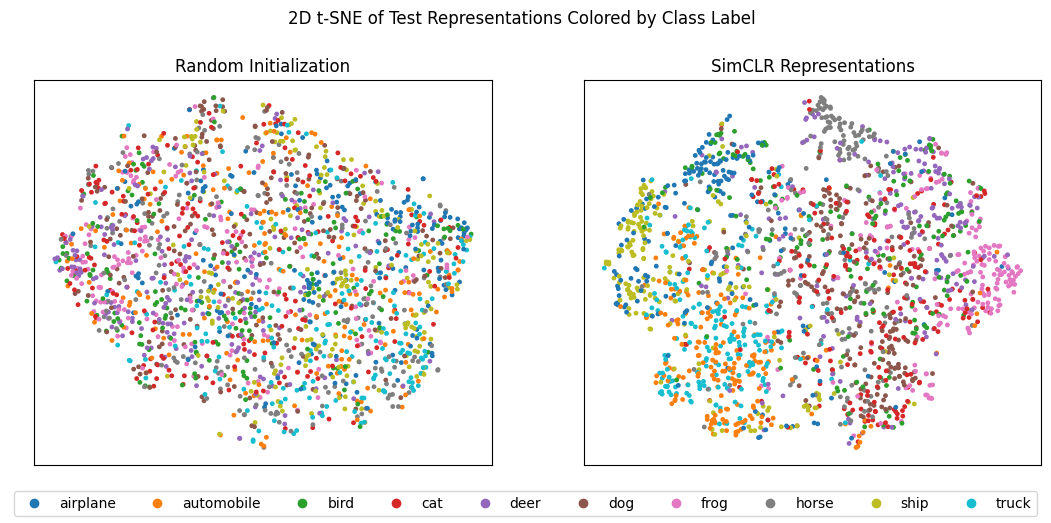

In [16]:
from sklearn.manifold import TSNE

subset = torch.randperm(len(simclr_h_test))[:2000]

def embed_2d(features):
    return TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(
        features[subset].numpy())

simclr_2d = embed_2d(simclr_h_test)
random_2d = embed_2d(random_h_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, pts, title in [(axes[0], random_2d, "Random Initialization"),
                       (axes[1], simclr_2d, "SimCLR Representations")]:
    scatter = ax.scatter(pts[:, 0], pts[:, 1], c=y_test[subset].numpy(), cmap="tab10", s=6)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
fig.legend(handles=scatter.legend_elements()[0], labels=classes, loc="lower center", ncol=10)
plt.suptitle("2D t-SNE of Test Representations Colored by Class Label", y=1.02)
plt.show()


<div dir="rtl" style="direction: rtl; text-align: right; font-family: Tahoma, 'Vazirmatn', sans-serif; line-height: 1.8;">
  <h1 dir="rtl" style="direction: rtl; text-align: right;">بخش ۷ · اصول نظری و اثبات‌های معماری (<span dir="ltr">§7 · Theoretical Principles &amp; Architectural Proofs</span>)</h1>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    <strong>اصل ۷.۱ (ضرورت ترکیب داده‌افزایی‌ها - <span dir="ltr">Principle 7.1: Necessity of Augmentation Composition</span>).</strong><br />
    یادگیری مقابله‌ای در صورتی که داده‌افزایی‌ها اجازه میانبرهای آماری سطحی (<span dir="ltr">Superficial Statistical Shortcuts</span>) را بدهند، با شکست روبه‌رو می‌شود:
  </p>
  <ul dir="rtl" style="direction: rtl; text-align: right; padding-right: 25px;">
    <li>اگر صرفاً از برش تصادفی (<span dir="ltr">Random Cropping</span>) استفاده شود، هیستوگرام رنگ تصویر در نماهای مختلف یکسان باقی می‌ماند؛ در نتیجه کدگذار می‌تواند وظیفه مقابله‌ای را صرفاً با تطبیق توزیع رنگ حل کند، به جای اینکه معناشناسی صحنه (<span dir="ltr">Scene Semantics</span>) را فراگیرد.</li>
    <li>اگر تنها از اعوجاج و آشفتگی رنگ (<span dir="ltr">Color Distortion</span>) استفاده شود، ساختارهای مکانی و مرزهای هندسی اشیاء تغییر نمی‌کنند و میانبرهای مکانی ایجاد می‌شوند.</li>
  </ul>
  <p dir="rtl" style="direction: rtl; text-align: right;">
    مدل <span dir="ltr">SimCLR</span> اثبات می‌کند که ترکیب همزمان برش مکانی تصادفی و آشفتگی شدید رنگ (<span dir="ltr">Composition of random spatial cropping and aggressive color jitter</span>) برای حذف کامل میانبرهای سطح پایین الزامی است و کدگذار مبتنی بر شبکه عصبی پیچشی (<span dir="ltr">CNN Encoder</span>) را وادار به یادگیری ویژگی‌های معنایی ناورا (<span dir="ltr">Invariant Semantic Features</span>) می‌سازد.
  </p>
  <hr style="margin: 1.5em 0;" />
  <p dir="rtl" style="direction: rtl; text-align: right;">
    <strong>اصل ۷.۲ (نقش نرمال‌سازی روی ابرکره - <span dir="ltr">Principle 7.2: Role of Hypersphere Normalization</span>).</strong><br />
    حذف نرمال‌سازی <span dir="ltr">L2</span> (<span dir="ltr">L2 Normalization</span>) و استفاده از ضرب داخلی خام (<span dir="ltr">$\mathbf{u}\cdot\mathbf{v}$</span>) به جای شباهت کسینوسی، آموزش مقابله‌ای را مختل می‌کند:
  </p>
  <ul dir="rtl" style="direction: rtl; text-align: right; padding-right: 25px;">
    <li>بدون قید نرم واحد (<span dir="ltr">Unit-Norm Constraints</span>)، تابع زیان می‌تواند بدون چرخش و اصلاح جهت بردار ویژگی‌ها، صرفاً با راندن نرم بردار جفت‌های مثبت به سمت بی‌نهایت (<span dir="ltr">$\|\mathbf{z}_i\| \to \infty$</span>) و فروپاشی نرم بردارهای منفی به سمت صفر (<span dir="ltr">$\mathbf{z}_k \to \mathbf{0}$</span>) کمینه شود.</li>
    <li>محدود کردن بازنمایی‌ها به ابرکره (<span dir="ltr">Hypersphere $S^{d-1}$</span>)، دستکاری طول بردار به عنوان درجه آزادی را مسدود کرده و بهینه‌سازی را منحصراً به هم‌ترازی زاویه‌ای (<span dir="ltr">Angular Alignment</span>) و پراکندگی یکنواخت (<span dir="ltr">Uniform Dispersion</span>) روی منیفلد محدود می‌سازد.</li>
  </ul>
</div>
